c:\Users\pappo\Documents\Python\Testen
U heeft 20 metingen gedaan.
Minimum moet kleiner zijn dan Maximum
U heeft minimaal: -10.0 en maximaal: 20.0 gekozen.
Ongeldige keuze, kies boven of onder
Uitschieters: [15.42, 15.07, 18.36, 17.04]


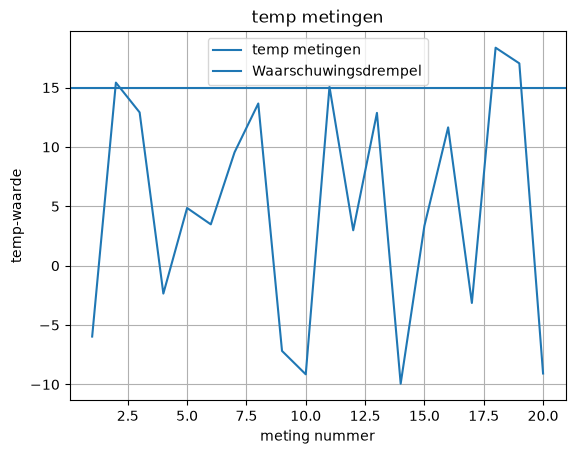

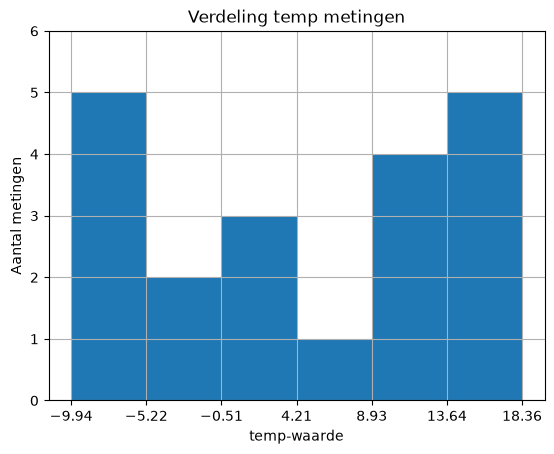

Aantal metingen: 20
Gemiddelde: 4.72
Minimum: -9.94
Maximum: 18.36
Standaardafwijking: 9.53
Aantal waarschuwingen: 4


In [7]:
import random
import numpy as np
import matplotlib.pyplot as plt
import csv



import os

print(os.getcwd())




def getal_invoeren(vraag):
    getal = input(vraag)

    while True:
        try:
            getal = float(getal)
            break
        except ValueError:
            print("Voer een geldig getal in")
            getal = input(vraag)

    return getal

# 1. Gebruikers input
def gebruiker_input():

    type = input("Wat is er gemeten?: ")

    aantal = input("Hoeveel metingen heb je gedaan?: ")
    while not aantal.isdigit() or int(aantal) <= 0:
        print("Voer alleen cijfers hoger dan 0 in")
        aantal = input("Hoeveel metingen heb je gedaan?: ")
    aantal = int(aantal)

    print(f'U heeft {aantal} metingen gedaan.')



    Min = getal_invoeren("Minimale sensor waarde: ")
    Max = getal_invoeren("Maximale sensor waarde: ")
    while Min>= Max:
        print("Minimum moet kleiner zijn dan Maximum")

        Min = getal_invoeren("Minimale sensor waarde: ")
        Max = getal_invoeren("Maximale sensor waarde: ")

    print(f'U heeft minimaal: {Min} en maximaal: {Max} gekozen.')


    richting = input("Waarschuwen boven of onder de drempel? (boven/onder): ").lower()
    while richting not in ["boven", "onder"]:
        print("Ongeldige keuze, kies boven of onder")
        richting = input("Waarschuwen boven of onder de drempel? (boven/onder): ").lower()
    Waarschuw = getal_invoeren("Waarschuwingsdrempel: ")

    
    
    return type, aantal, Min, Max, Waarschuw, richting

# 2. Random waardes
def waardes_genereren(aantal, minimum, maximum):
    random.seed(1)

    waardes = []

    for i in range(aantal):
        waarde = round(random.uniform(minimum, maximum), 2)
        waardes.append(waarde)

    return waardes

# 3. Uitschieters zoeken
def find_outliers(metingen, threshold, richting):

    uitschieters = []

    for meting in metingen:
        if richting == "boven" and meting > threshold:
            uitschieters.append(meting)

        elif richting == "onder" and meting < threshold:
            uitschieters.append(meting)

    return uitschieters

# 4. Data
def Analyze_NumPy(metingen, threshold, richting):
    metingen = np.array(metingen)
    aantal = len(metingen)
    gemiddelde = np.mean(metingen)
    minimum = np.min(metingen)
    maximum = np.max(metingen)
    standaardafwijking = np.std(metingen)
    
    if richting == "boven":
        aantal_waarschuwingen = np.sum(metingen > threshold)
    elif richting == "onder":
        aantal_waarschuwingen = np.sum(metingen < threshold)

    return aantal, gemiddelde, minimum, maximum, standaardafwijking, aantal_waarschuwingen

# 5. Grafiek
def Grafiek_maken(metingen, waarschuwingsdrempel, sensortype):
    plt.plot(range(1, len(metingen) + 1), metingen, label=f"{sensortype} metingen")
    plt.axhline(waarschuwingsdrempel, label="Waarschuwingsdrempel")

    plt.title(f"{sensortype} metingen")
    plt.xlabel("meting nummer")
    plt.ylabel(f"{sensortype}-waarde")
    plt.grid()
    plt.legend()
    plt.show()

# 6. Histogram maken
def histogram_maken(metingen, sensortype):
    aantallen, grenzen, _ = plt.hist(metingen, bins="auto")
    plt.title(f"Verdeling {sensortype} metingen")
    plt.xlabel(f"{sensortype}-waarde")
    plt.ylabel("Aantal metingen")
    plt.yticks(range(0, int(max(aantallen)) + 2))
    plt.xticks(grenzen)
    plt.grid()
    plt.show()

# 7. Data opslaan
def Opslaan(metingen, sensortype):
    
    try:
        with open("sensor_metingen.csv", "w", newline="") as bestand:
            schrijven = csv.writer(bestand)

            schrijven.writerow(["Meting nummer", f"{sensortype}waarde"])

            for i in range(len(metingen)):
                schrijven.writerow([i + 1, metingen[i]])
    except OSError:
        print("Fout bij het opslaan van het CSV-bestand.")

# 8. CSV inladen
def CSV_inladen():
    waardes = []

    try:
        with open("sensor_metingen.csv", "r") as bestand:
            lezen = csv.reader(bestand)
            next(lezen)
            for regel in lezen:
                waardes.append(float(regel[1]))

    except OSError:
        print("Fout bij het inladen van het CSV-bestand.")
    print("Ingelezen waardes:", waardes)
    return waardes


# 9. Hoofdprogramma
def main():

    keuze = input("Wilt u nieuwe gegevens of oude gegevens inladen (nieuw/inladen): ")
    keuze = keuze.lower()
    while keuze not in ["nieuw", "inladen"]:
        print("Ongeldige keuze, kies nieuw of inladen")
        keuze = input("Wilt u nieuwe gegevens of oude gegevens inladen (nieuw/inladen): ").lower()

    if keuze == "nieuw":
        sensortype, aantal, minimum, maximum, threshold, richting = gebruiker_input()
        waardes = waardes_genereren(aantal, minimum, maximum)
        Opslaan(waardes, sensortype)
        

    elif keuze == "inladen":
        waardes = CSV_inladen()
        sensortype = input("Sensortype: ")
        richting = input("Waarschuwen boven of onder de drempel? (boven/onder): ").lower()
        while richting not in ["boven", "onder"]:
            print("Ongeldige keuze, kies boven of onder")
            richting = input("Waarschuwen boven of onder de drempel? (boven/onder): ").lower()
        threshold = getal_invoeren("Waarschuwingsdrempel: ")
        
        
       
    uitschieters = find_outliers(waardes, threshold, richting)
    statistieken = Analyze_NumPy(waardes, threshold, richting)
    print("Uitschieters:", uitschieters)
    Grafiek_maken(waardes, threshold, sensortype)
    histogram_maken(waardes, sensortype)

    print("Aantal metingen:", statistieken[0])
    print("Gemiddelde:", round(statistieken[1],2))
    print("Minimum:", statistieken[2])
    print("Maximum:", statistieken[3])
    print("Standaardafwijking:", round(statistieken[4],2))
    print("Aantal waarschuwingen:", statistieken[5])


    
    

# Programma starten
if __name__ == "__main__":
    main()
